# 🏦 Indian Banking Transactions
| **Dataset** | `indian_banking_transactions.csv` — 550,000 transactions, 20 columns, Jan 2019 – Jan 2024 |

Problem Statement & Objectives

A bank records every transaction with details about the customer, account, channel, location and whether the transaction was fraudulent. This project explores that data end-to-end using the tools like NumPy → Pandas → Cleaning → Transformation → Indexing/Merging → GroupBy & Time Series → Matplotlib → Seaborn.

**Questions we try to answer**
1. Which transaction types, channels, states and merchant categories drive the most transaction value?
2. How do transactions trend over time (monthly, quarterly, yearly, by hour of day)?
3. Is fraud linked to channel, hour of day, KYC status, credit score or transaction type?
4. How often do transactions fail, and where?
5. What does the typical customer look like (credit rating, loans, balances)?

## Setup

Load the libraries we need and read the dataset once

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from google.colab import files
uploaded = files.upload()

Saving indian_banking_transactions.csv to indian_banking_transactions.csv


In [8]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

df = pd.read_csv('indian_banking_transactions.csv')
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (550000, 20)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,01-01-2019,15:28,Current,UPI,"1,820.17",Debit,"609,365.31",Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,01-01-2019,03:00,Current,UPI,392.67,Credit,"14,451.14",Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,01-01-2019,18:03,Fixed Deposit,POS,"1,255.97",Debit,"47,621.87",Utilities,Punjab,813,1,Home,"1,433.91",Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,01-01-2019,08:03,Savings,UPI,"2,580.68",Debit,"34,467.85",Travel,Karnataka,628,1,Personal,"6,280.35",Success,API,Verified,0,8
4,TXN000000005,CUST006266,01-01-2019,14:23,Fixed Deposit,UPI,"2,573.80",Debit,"26,617.40",Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


UNDERSTANDING DATA

In [9]:
print('Shape (rows, columns):', df.shape)
print('Number of elements   :', df.size)
print('Column names         :', df.columns.tolist())
print('Index                :', df.index)
print('\nData types:')
print(df.dtypes)

Shape (rows, columns): (550000, 20)
Number of elements   : 11000000
Column names         : ['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour']
Index                : RangeIndex(start=0, stop=550000, step=1)

Data types:
transaction_id            object
customer_id               object
transaction_date          object
transaction_time          object
account_type              object
transaction_type          object
transaction_amount       float64
transaction_direction     object
account_balance          float64
merchant_category         object
state                     object
credit_score               int64
has_loan                   int64
loan_type                 object
emi_amount               float

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         550000 non-null  object 
 1   customer_id            550000 non-null  object 
 2   transaction_date       550000 non-null  object 
 3   transaction_time       550000 non-null  object 
 4   account_type           550000 non-null  object 
 5   transaction_type       550000 non-null  object 
 6   transaction_amount     550000 non-null  float64
 7   transaction_direction  550000 non-null  object 
 8   account_balance        550000 non-null  float64
 9   merchant_category      550000 non-null  object 
 10  state                  550000 non-null  object 
 11  credit_score           550000 non-null  int64  
 12  has_loan               550000 non-null  int64  
 13  loan_type              172866 non-null  object 
 14  emi_amount             550000 non-nu

In [11]:
# Numerical summary statistics
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,"550,000.00","29,907.09","139,610.10",2.40,763.04,"2,035.74","8,557.50","10,000,000.00"
account_balance,"550,000.00","84,550.12","170,914.59",500.00,"15,157.78","36,422.87","87,607.04","5,000,000.00"
credit_score,"550,000.00",599.81,173.05,300.00,450.00,600.00,750.00,899.00
has_loan,"550,000.00",0.35,0.48,0.00,0.00,0.00,1.00,1.00
emi_amount,"550,000.00","2,365.86","4,973.55",0.00,0.00,0.00,"3,115.03","153,325.74"
is_fraud,"550,000.00",0.01,0.09,0.00,0.00,0.00,0.00,1.00
transaction_hour,"550,000.00",11.50,6.92,0.00,6.00,11.00,17.00,23.00


In [12]:
# Categorical summary + unique value counts
print(df.select_dtypes(exclude='number').describe().T)
print('\nUnique values per column:')
print(df.nunique())
print('\nTransactions per state:')
print(df['state'].value_counts())

                        count  unique           top    freq
transaction_id         550000  550000  TXN000549984       1
customer_id            550000   79916    CUST003688      20
transaction_date       550000    1827    11-11-2023     373
transaction_time       550000    1440         06:25     448
account_type           550000       5       Savings  219651
transaction_type       550000      10           UPI  153986
transaction_direction  550000       2         Debit  370394
merchant_category      550000      15        Retail   66180
state                  550000      10   Maharashtra   98911
loan_type              172866       6      Personal   47810
transaction_status     550000       4       Success  506247
channel                550000       6    Mobile_App  208368
kyc_status             550000       3      Verified  483457

Unique values per column:
transaction_id           550000
customer_id               79916
transaction_date           1827
transaction_time           1440
accou

# **Data Cleaning and Preprocessing**



Handling Missing Data

In [13]:
missing = df.isna().sum()
print('Missing values per column (only columns with gaps):')
print(missing[missing > 0])
print('\nPercentage missing in loan_type:', round(df['loan_type'].isna().mean() * 100, 2), '%')

# What explains the gaps?  Cross-check with has_loan
print('\nMissing loan_type split by has_loan:')
print(df[df['loan_type'].isna()]['has_loan'].value_counts())

Missing values per column (only columns with gaps):
loan_type    377134
dtype: int64

Percentage missing in loan_type: 68.57 %

Missing loan_type split by has_loan:
has_loan
0    357712
1     19422
Name: count, dtype: int64


In [14]:
# --- fillna: replace the gaps with a meaningful label ---
# has_loan == 0  -> the customer has no loan        -> 'No Loan'
# has_loan == 1  -> loan exists but type not stored -> 'Unknown'
fill_values = pd.Series(np.where(df['has_loan'] == 1, 'Unknown', 'No Loan'), index=df.index)
df['loan_type'] = df['loan_type'].fillna(fill_values)

print('\nMissing loan_type after fillna:', df['loan_type'].isna().sum())
print(df['loan_type'].value_counts())


Missing loan_type after fillna: 0
loan_type
No Loan      357712
Personal      47810
Home          38252
Auto          29219
Business      28863
Unknown       19422
Education     19074
Gold           9648
Name: count, dtype: int64


Replacing Values and Data Type Conversion


In [15]:
# --- replace(): make channel labels readable (underscore -> space) ---
df['channel'] = df['channel'].replace({'Mobile_App': 'Mobile App', 'POS_Terminal': 'POS Terminal'})
print('Channels now:', df['channel'].unique().tolist())

# --- str.replace(): same idea applied to a whole column ---
df['transaction_type'] = df['transaction_type'].str.replace('_', ' ')
print('Transaction types now:', df['transaction_type'].unique().tolist())

Channels now: ['Branch', 'Mobile App', 'API', 'Web', 'ATM', 'POS Terminal']
Transaction types now: ['UPI', 'POS', 'Net Banking', 'NEFT', 'Credit Card', 'Cheque', 'ATM Withdrawal', 'IMPS', 'RTGS', 'Auto Debit']


In [16]:
# --- Text -> real datetime ---
df['transaction_date'] = pd.to_datetime(df['transaction_date'], format='%d-%m-%Y')
# date + time-of-day -> one full timestamp
df['transaction_datetime'] = df['transaction_date'] + pd.to_timedelta(df['transaction_time'] + ':00')
print('transaction_date dtype    :', df['transaction_date'].dtype)
print('Date range:', df['transaction_date'].min().date(), '->', df['transaction_date'].max().date())

# --- Repeated text -> 'category' dtype (smaller in memory, faster to group by) ---
cat_cols = ['account_type', 'transaction_type', 'transaction_direction', 'merchant_category',
            'state', 'loan_type', 'transaction_status', 'channel', 'kyc_status']
df[cat_cols] = df[cat_cols].astype('category')

# --- Numeric flags -> compact integer types ---
df['is_fraud'] = df['is_fraud'].astype('int8')
df['has_loan'] = df['has_loan'].astype('int8')
df['credit_score'] = df['credit_score'].astype('int16')

transaction_date dtype    : datetime64[ns]
Date range: 2019-01-01 -> 2024-01-01


Detecting and Removing Duplicates

In [17]:
print('Fully duplicated rows   :', df.duplicated().sum())
print('Duplicate transaction IDs:', df['transaction_id'].duplicated().sum())
print('Repeat customers (customer_id appears more than once):',
      df['customer_id'].duplicated().sum(), ' <- expected: one customer makes many transactions')

df = df.drop_duplicates(subset='transaction_id')
print('\nShape after drop_duplicates():', df.shape)

Fully duplicated rows   : 0
Duplicate transaction IDs: 0
Repeat customers (customer_id appears more than once): 470084  <- expected: one customer makes many transactions

Shape after drop_duplicates(): (550000, 21)


Data Validation and Outlier Detection

In [18]:
# Basic sanity checks
print('Non-positive amounts :', (df['transaction_amount'] <= 0).sum())
print('Negative balances    :', (df['account_balance'] < 0).sum())
print('Credit scores outside 300-900:', (~df['credit_score'].between(300, 900)).sum())
print('Hours outside 0-23   :', (~df['transaction_hour'].between(0, 23)).sum())

Non-positive amounts : 0
Negative balances    : 0
Credit scores outside 300-900: 0
Hours outside 0-23   : 0


# **Data Transformation and Categorization**



Mapping and Renaming Values

In [19]:
# .map(): each value -> another value through a lookup dictionary
df['fraud_label'] = df['is_fraud'].map({0: 'Normal', 1: 'Fraudulent'})
df['loan_flag'] = df['has_loan'].map({0: 'No', 1: 'Yes'})
print(df['fraud_label'].value_counts())

# .rename(): clearer column names (returns a new frame, original stays intact)
df_renamed = df.rename(columns={'transaction_amount': 'amount', 'transaction_type': 'txn_type'})
print('\nRenamed columns:', [c for c in df_renamed.columns if c in ('amount', 'txn_type')])

# Permanent rename of one column for readability in later sections
df = df.rename(columns={'transaction_hour': 'hour'})
df['fraud_label'] = df['fraud_label'].astype('category')

fraud_label
Normal        545127
Fraudulent      4873
Name: count, dtype: int64

Renamed columns: ['txn_type', 'amount']


Binning and Categorization

`pd.cut` groups values into bins **you define** (fixed edges).
`pd.qcut` groups values into bins with **equal numbers of rows** (quantiles).

In [20]:
# pd.cut: fixed credit-score ranges -> readable ratings
score_bins = [300, 580, 670, 740, 800, 900]
score_labels = ['Poor', 'Fair', 'Good', 'Very Good', 'Excellent']
df['credit_rating'] = pd.cut(df['credit_score'], bins=score_bins, labels=score_labels, include_lowest=True)
print(df['credit_rating'].value_counts().sort_index())

# pd.cut: hour of day -> time-of-day bucket
df['time_of_day'] = pd.cut(df['hour'], bins=[-1, 5, 11, 17, 23],
                           labels=['Night (0-5)', 'Morning (6-11)', 'Afternoon (12-17)', 'Evening (18-23)'])
print('\n', df['time_of_day'].value_counts().sort_index())

# pd.cut: custom amount bands
df['amount_band'] = pd.cut(df['transaction_amount'], bins=[0, 1000, 10000, 50000, 100000, np.inf],
                           labels=['Micro (<1K)', 'Small (1K-10K)', 'Medium (10K-50K)', 'Large (50K-1L)', 'Very Large (>1L)'])
print('\n', df['amount_band'].value_counts().sort_index())

credit_rating
Poor         257168
Fair          83064
Good          64016
Very Good     54793
Excellent     90959
Name: count, dtype: int64

 time_of_day
Night (0-5)          137167
Morning (6-11)       137987
Afternoon (12-17)    137394
Evening (18-23)      137452
Name: count, dtype: int64

 amount_band
Micro (<1K)         182768
Small (1K-10K)      242205
Medium (10K-50K)     69194
Large (50K-1L)       19754
Very Large (>1L)     36079
Name: count, dtype: int64


In [21]:
# pd.qcut: 3 equal-sized tiers (by count, not by value range)
df['amount_tier'] = pd.qcut(df['transaction_amount'], q=3, labels=['Low', 'Medium', 'High'])
print(df['amount_tier'].value_counts())
print('\nAmount range inside each tier:')
print(df.groupby('amount_tier', observed=True)['transaction_amount'].agg(['min', 'max']).round(2))

amount_tier
Medium    190710
Low       183333
High      175957
Name: count, dtype: int64

Amount range inside each tier:
                 min           max
amount_tier                       
Low             2.40      1,005.43
Medium      1,005.45      5,000.00
High        5,000.01 10,000,000.00


Sorting, Filtering

In [22]:
# --- Sorting ---
print('Top 5 transactions by amount:')
print(df.sort_values('transaction_amount', ascending=False)[['transaction_id', 'transaction_amount', 'state']].head())

print('\nSort by two columns (state A-Z, amount high-low):')
print(df.sort_values(['state', 'transaction_amount'], ascending=[True, False])[['state', 'transaction_amount']].head())

Top 5 transactions by amount:
       transaction_id  transaction_amount        state
371877   TXN000371878       10,000,000.00           UP
386302   TXN000386303       10,000,000.00    Karnataka
526796   TXN000526797       10,000,000.00    Telangana
532757   TXN000532758       10,000,000.00        Delhi
432561   TXN000432562        9,236,223.15  Maharashtra

Sort by two columns (state A-Z, amount high-low):
        state  transaction_amount
532757  Delhi       10,000,000.00
304923  Delhi        6,240,564.07
545408  Delhi        5,919,975.71
333962  Delhi        4,652,663.29
207816  Delhi        4,430,621.43


In [23]:
# --- Filtering ---
high_value_mobile = df[(df['transaction_amount'] > 50000) & (df['channel'] == 'Mobile App')]
print('High-value (> Rs 50,000) Mobile App transactions:', len(high_value_mobile))

failed_night = df[(df['transaction_status'] == 'Failed') & (df['hour'].between(0, 5))]
print('Failed transactions between midnight and 5 AM   :', len(failed_night))

High-value (> Rs 50,000) Mobile App transactions: 21271
Failed transactions between midnight and 5 AM   : 5442


# **Hierarchical Indexing**
*Multi-level indexing · Concatenating · Reshaping with `stack`, `unstack`, `pivot`*

Multi-level (Hierarchical) Indexing

In [24]:
state_type = df.groupby(['state', 'transaction_type'], observed=True).agg(
    transactions=('transaction_id', 'count'),
    total_amount=('transaction_amount', 'sum')
)
print('Index type  :', type(state_type.index).__name__)
print('Index levels:', state_type.index.names)
state_type.head(10)

Index type  : MultiIndex
Index levels: ['state', 'transaction_type']


transactions     total_amount
state transaction_type                               
Delhi ATM Withdrawal            6614    16,035,000.00
      Auto Debit                3350     9,118,048.59
      Cheque                    2589   347,477,156.96
      Credit Card               2041     9,628,174.12
      IMPS                      9143    66,158,308.90
      NEFT                      8202   340,512,175.69
      Net Banking               4623    99,271,896.10
      POS                       7179    14,637,523.06
      RTGS                      3977 1,054,187,572.30
      UPI                      18396    24,748,345.63

In [25]:
# Selecting from a MultiIndex
print('All rows for Delhi:')
print(state_type.loc['Delhi'])

print('\nOne exact row (Delhi, UPI):')
print(state_type.loc[('Delhi', 'UPI')])

print('\nAggregate over one level (total per state):')
print(state_type.groupby(level='state')['total_amount'].sum().round(0))

All rows for Delhi:
                  transactions     total_amount
transaction_type                               
ATM Withdrawal            6614    16,035,000.00
Auto Debit                3350     9,118,048.59
Cheque                    2589   347,477,156.96
Credit Card               2041     9,628,174.12
IMPS                      9143    66,158,308.90
NEFT                      8202   340,512,175.69
Net Banking               4623    99,271,896.10
POS                       7179    14,637,523.06
RTGS                      3977 1,054,187,572.30
UPI                      18396    24,748,345.63

One exact row (Delhi, UPI):
transactions       18,396.00
total_amount   24,748,345.63
Name: (Delhi, UPI), dtype: float64

Aggregate over one level (total per state):
state
Delhi         1,981,774,201.00
Gujarat       1,682,204,920.00
Karnataka     2,256,631,611.00
Maharashtra   2,980,264,902.00
Punjab          646,932,071.00
Rajasthan     1,170,165,310.00
Tamil Nadu    2,148,851,576.00
Telangana     

/tmp/ipykernel_1017/1568180329.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(state_type.groupby(level='state')['total_amount'].sum().round(0))


Reshaping with `stack`, `unstack`, and `pivot`



In [26]:
# unstack(): move the 'transaction_type' index level into columns
state_type_matrix = state_type['transactions'].unstack(fill_value=0)
print('Unstacked (rows = state, columns = transaction type):')
state_type_matrix

Unstacked (rows = state, columns = transaction type):


transaction_type,ATM Withdrawal,Auto Debit,Cheque,Credit Card,IMPS,NEFT,Net Banking,POS,RTGS,UPI
state,,,,,,,,,,
Delhi,6614,3350,2589,2041,9143,8202,4623,7179,3977,18396
Gujarat,5458,2672,2142,1678,7591,6673,3789,6136,3349,15310
Karnataka,7802,3853,3001,2338,10749,9196,5329,8440,4450,21501
Maharashtra,9898,4951,3995,2808,13817,11939,7003,10771,6010,27719
Punjab,2285,1046,902,657,3048,2592,1562,2461,1315,6204
Rajasthan,3836,1908,1538,1146,5612,4677,2589,4258,2345,10816
Tamil Nadu,7068,3652,2755,2182,10026,8827,5032,7792,4350,20063
Telangana,5040,2398,1980,1426,6973,6024,3495,5488,2865,13921
UP,2730,1357,1085,803,3946,3226,1943,3021,1663,7640


In [27]:
# pivot(): reshape long -> wide (needs unique index/column pairs, so we use a summary table)
summary = df.groupby(['state', 'channel'], observed=True)['transaction_amount'].sum().reset_index()
pivoted = summary.pivot(index='state', columns='channel', values='transaction_amount')
print('\npivot(): total amount by state x channel')
pivoted.round(0)


pivot(): total amount by state x channel


channel,API,ATM,Branch,Mobile App,POS Terminal,Web
state,,,,,,
Delhi,"125,115,850.00","247,184,300.00","186,563,843.00","780,799,787.00","213,016,742.00","429,093,681.00"
Gujarat,"131,525,251.00","188,096,585.00","175,840,188.00","635,884,241.00","180,694,344.00","370,164,311.00"
Karnataka,"164,992,488.00","276,873,167.00","201,997,078.00","887,935,456.00","250,772,496.00","474,060,926.00"
Maharashtra,"207,818,173.00","352,033,314.00","310,428,721.00","1,090,417,947.00","316,710,547.00","702,856,199.00"
Punjab,"55,818,011.00","61,970,272.00","55,854,577.00","265,316,134.00","71,311,860.00","136,661,217.00"
Rajasthan,"71,086,071.00","143,523,592.00","124,628,546.00","432,776,068.00","134,459,827.00","263,691,206.00"
Tamil Nadu,"145,113,852.00","257,869,334.00","201,920,876.00","806,105,075.00","235,798,346.00","502,044,093.00"
Telangana,"103,324,497.00","176,328,784.00","144,013,221.00","535,891,330.00","154,185,619.00","313,086,808.00"
UP,"63,092,528.00","106,239,446.00","80,773,301.00","321,448,410.00","93,104,622.00","175,337,715.00"


In [28]:
# pivot_table(): pivot + aggregation (works even when pairs repeat)
pivot = pd.pivot_table(df, index='state', columns='transaction_type', values='transaction_amount',
                       aggfunc='sum', observed=True, fill_value=0, margins=True, margins_name='Total')
print('pivot_table(): total amount by state and type, with totals')
pivot.round(0)

pivot_table(): total amount by state and type, with totals


transaction_type,ATM Withdrawal,Auto Debit,Cheque,Credit Card,IMPS,NEFT,Net Banking,POS,RTGS,UPI,Total
state,,,,,,,,,,,
Delhi,"16,035,000.00","9,118,049.00","347,477,157.00","9,628,174.00","66,158,309.00","340,512,176.00","99,271,896.00","14,637,523.00","1,054,187,572.00","24,748,346.00","1,981,774,201.00"
Gujarat,"13,292,000.00","7,193,488.00","298,832,883.00","8,912,695.00","54,320,665.00","254,927,739.00","82,230,649.00","12,183,103.00","929,091,898.00","21,219,801.00","1,682,204,920.00"
Karnataka,"18,816,000.00","10,180,916.00","390,480,623.00","11,998,339.00","73,654,666.00","392,408,306.00","109,452,667.00","16,576,124.00","1,203,897,671.00","29,166,300.00","2,256,631,611.00"
Maharashtra,"24,250,000.00","13,612,514.00","509,425,782.00","14,178,069.00","97,826,838.00","479,488,283.00","146,446,186.00","21,539,147.00","1,635,070,806.00","38,427,275.00","2,980,264,902.00"
Punjab,"5,395,000.00","2,692,250.00","114,383,559.00","3,426,198.00","20,948,122.00","98,658,531.00","35,038,755.00","4,864,630.00","353,283,848.00","8,241,178.00","646,932,071.00"
Rajasthan,"9,256,000.00","5,138,886.00","197,911,188.00","5,716,075.00","40,123,703.00","188,585,503.00","54,178,794.00","8,797,429.00","645,667,301.00","14,790,430.00","1,170,165,310.00"
Tamil Nadu,"17,145,000.00","9,902,770.00","340,599,513.00","11,272,055.00","68,558,241.00","379,981,416.00","112,145,125.00","15,261,543.00","1,166,728,787.00","27,257,126.00","2,148,851,576.00"
Telangana,"12,063,000.00","6,623,026.00","267,185,172.00","6,706,047.00","47,940,264.00","250,317,646.00","73,054,620.00","11,019,595.00","733,526,772.00","18,394,117.00","1,426,830,259.00"
UP,"6,661,500.00","3,657,616.00","141,518,782.00","3,913,668.00","27,932,448.00","151,033,255.00","40,895,444.00","5,955,421.00","448,293,052.00","10,134,836.00","839,996,022.00"


# **GroupBy and Time Series Analysis**
*Grouping and aggregation · Time series conversion and indexing · Resampling, frequency conversion and date-based selection*

In [29]:
# Single-key groupby
print('Average amount by channel:')
print(df.groupby('channel', observed=True)['transaction_amount'].mean().round(2))


Average amount by channel:
channel
API            30,261.39
ATM            29,624.41
Branch         29,224.44
Mobile App     29,966.36
POS Terminal   29,698.19
Web            30,261.60
Name: transaction_amount, dtype: float64


In [30]:
# agg with several functions at once
print(df.groupby('transaction_direction', observed=True)['transaction_amount'].agg(['count', 'sum', 'mean', 'median', 'max']).round(2))

# Top 2 largest transactions in each state
print('\nTop 2 transactions per state:')
print(df.sort_values('transaction_amount', ascending=False).groupby('state', observed=True).head(2)
        .sort_values(['state', 'transaction_amount'], ascending=[True, False])[['state', 'transaction_amount']])

                        count              sum      mean   median  \
transaction_direction                                               
Credit                 179606 7,655,754,979.94 42,625.27 3,041.32   
Debit                  370394 8,793,146,683.62 23,739.98 2,000.00   

                                max  
transaction_direction                
Credit                10,000,000.00  
Debit                 10,000,000.00  

Top 2 transactions per state:
              state  transaction_amount
532757        Delhi       10,000,000.00
304923        Delhi        6,240,564.07
292404      Gujarat        5,875,635.26
326643      Gujarat        5,261,880.75
386302    Karnataka       10,000,000.00
374249    Karnataka        7,187,119.16
432561  Maharashtra        9,236,223.15
242296  Maharashtra        7,899,297.23
418681       Punjab        8,009,499.04
423542       Punjab        7,923,295.55
212259    Rajasthan        7,698,537.27
357388    Rajasthan        6,751,663.36
440908   Tamil Nadu 

In [31]:
# Make the timestamp the index (DatetimeIndex) and sort it
ts = df.set_index('transaction_datetime').sort_index()
print(type(ts.index).__name__, '| first:', ts.index.min(), '| last:', ts.index.max())

# Date-based selection with partial strings
print('\nAll of 2021              :', len(ts.loc['2021']))
print('March - June 2022        :', len(ts.loc['2022-03':'2022-06']))
print('Single day 2020-12-25    :', len(ts.loc['2020-12-25']))
print('Night transactions (22:00-05:00):', len(ts.between_time('22:00', '05:00')))


DatetimeIndex | first: 2019-01-01 00:01:00 | last: 2024-01-01 23:58:00

All of 2021              : 110024
March - June 2022        : 36792
Single day 2020-12-25    : 285
Night transactions (22:00-05:00): 161187


In [32]:
# Resample: group by time period (MS = month start, QS = quarter start, YS = year start)
monthly = ts.resample('MS').agg(
    transactions=('transaction_id', 'count'),
    total_amount=('transaction_amount', 'sum'),
    avg_amount=('transaction_amount', 'mean'),
    fraud_cases=('is_fraud', 'sum')
)
monthly['fraud_rate'] = monthly['fraud_cases'] / monthly['transactions'] * 100

# the final month contains only 1 January 2024, so it is an incomplete month
print('Rows in last month:', monthly['transactions'].iloc[-1])
monthly = monthly.iloc[:-1]
print('Monthly series:', monthly.index.min().date(), '->', monthly.index.max().date(), f'({len(monthly)} months)')
monthly.head()

Rows in last month: 295
Monthly series: 2019-01-01 -> 2023-12-01 (60 months)


,transactions,total_amount,avg_amount,fraud_cases,fraud_rate
transaction_datetime,,,,,
2019-01-01,9406,"249,535,891.79","26,529.44",73,0.78
2019-02-01,8220,"243,173,588.54","29,583.16",76,0.92
2019-03-01,9290,"260,628,647.43","28,054.75",86,0.93
2019-04-01,8990,"273,646,411.65","30,438.98",100,1.11
2019-05-01,9425,"274,372,666.32","29,111.16",87,0.92


In [33]:
quarterly = ts['transaction_amount'].resample('QS').sum()
yearly = ts['transaction_amount'].resample('YS').agg(['count', 'sum', 'mean'])
yearly.index = yearly.index.year
print('Quarterly total amount (first 4):')
print(quarterly.head(4).round(0))
print('\nYearly summary:')
print(yearly.round(2))

# Frequency conversion: weekly totals -> daily frequency (forward-filled)
weekly = ts['transaction_amount'].resample('W').sum()
daily_from_weekly = weekly.asfreq('D', method='ffill')
print('\nWeekly points:', len(weekly), '-> after asfreq("D"):', len(daily_from_weekly))

Quarterly total amount (first 4):
transaction_datetime
2019-01-01   753,338,128.00
2019-04-01   813,993,380.00
2019-07-01   874,196,377.00
2019-10-01   816,937,348.00
Freq: QS-JAN, Name: transaction_amount, dtype: float64

Yearly summary:
                       count              sum      mean
transaction_datetime                                   
2019                  110083 3,258,465,232.49 29,600.08
2020                  109767 3,315,647,465.35 30,206.23
2021                  110024 3,253,234,935.54 29,568.41
2022                  110247 3,344,988,460.30 30,340.86
2023                  109584 3,265,949,139.69 29,803.16
2024                     295    10,616,430.19 35,987.90

Weekly points: 262 -> after asfreq("D"): 1828


In [34]:
# Seasonality: which calendar months are busiest?
seasonal = monthly.groupby(monthly.index.month)['transactions'].mean().round(0)
seasonal.index.name = 'month'
print('\nAverage transactions per calendar month:')
print(seasonal.to_frame().T)


Average transactions per calendar month:
month              1        2        3        4        5        6        7   \
transactions 9,374.00 8,408.00 9,266.00 8,966.00 9,344.00 9,083.00 9,384.00   

month              8        9        10       11       12  
transactions 9,401.00 9,011.00 9,365.00 9,051.00 9,287.00  


# **Q1 — Which transaction types, channels, states and merchant categories drive the most value?**


In [35]:
def summarize(col, sort_by='total_amount'):
    """Transactions, value, average ticket, share of value and fraud rate for each group in `col`."""
    out = df.groupby(col, observed=True).agg(
        transactions=('transaction_id', 'count'),
        total_amount=('transaction_amount', 'sum'),
        average_amount=('transaction_amount', 'mean'),
        fraud_cases=('is_fraud', 'sum'),
    )
    out['share_of_value_%'] = out['total_amount'] / out['total_amount'].sum() * 100
    out['fraud_rate_%'] = out['fraud_cases'] / out['transactions'] * 100
    return out.sort_values(sort_by, ascending=False)

total_value = df['transaction_amount'].sum()

# Transaction Type Analysis

In [36]:
type_summary = summarize('transaction_type')
type_summary

,transactions,total_amount,average_amount,fraud_cases,share_of_value_%,fraud_rate_%
transaction_type,,,,,,
RTGS,32964,"8,875,702,507.02","269,254.41",611,53.96,1.85
Cheque,21711,"2,830,289,647.44","130,362.01",256,17.21,1.18
NEFT,66615,"2,762,127,782.84","41,464.05",581,16.79,0.87
Net Banking,38458,"819,826,094.11","21,317.44",326,4.98,0.85
IMPS,77038,"540,769,059.32","7,019.51",624,3.29,0.81
UPI,153986,"209,238,290.51","1,358.81",1211,1.27,0.79
ATM Withdrawal,55106,"133,550,000.00","2,423.51",456,0.81,0.83
POS,60278,"120,342,458.44","1,996.46",481,0.73,0.80
Credit Card,16426,"82,904,444.66","5,047.15",140,0.50,0.85


# Banking Channel Analysis

In [37]:
channel_summary = summarize('channel')
channel_summary

,transactions,total_amount,average_amount,fraud_cases,share_of_value_%,fraud_rate_%
channel,,,,,,
Mobile App,208368,"6,244,030,594.43","29,966.36",1809,37.96,0.87
Web,121010,"3,661,956,282.79","30,261.60",1080,22.26,0.89
ATM,66177,"1,960,454,631.19","29,624.41",561,11.92,0.85
POS Terminal,60853,"1,807,223,728.89","29,698.19",557,10.99,0.92
Branch,54957,"1,606,087,589.44","29,224.44",520,9.76,0.95
API,38635,"1,169,148,836.82","30,261.39",346,7.11,0.90


# State-wise Banking Analysis

In [38]:
state_summary = summarize('state')
state_summary

,transactions,total_amount,average_amount,fraud_cases,share_of_value_%,fraud_rate_%
state,,,,,,
Maharashtra,98911,"2,980,264,901.72","30,130.77",885,18.12,0.89
Karnataka,76659,"2,256,631,611.09","29,437.27",701,13.72,0.91
Tamil Nadu,71747,"2,148,851,576.48","29,950.40",633,13.06,0.88
Delhi,66114,"1,981,774,201.35","29,975.11",588,12.05,0.89
Gujarat,54798,"1,682,204,920.36","30,698.29",482,10.23,0.88
Telangana,49610,"1,426,830,259.24","28,760.94",440,8.67,0.89
West Bengal,43950,"1,315,250,791.00","29,926.07",413,8.00,0.94
Rajasthan,38725,"1,170,165,309.56","30,217.31",303,7.11,0.78
UP,27414,"839,996,022.23","30,641.13",260,5.11,0.95


# Merchant Category Analysis

In [39]:
merchant_summary = summarize('merchant_category')
merchant_summary

,transactions,total_amount,average_amount,fraud_cases,share_of_value_%,fraud_rate_%
merchant_category,,,,,,
Retail,66180,"2,004,894,940.56","30,294.57",594,12.19,0.90
Food & Dining,54776,"1,650,395,103.08","30,129.89",471,10.03,0.86
E-Commerce,54767,"1,618,020,617.77","29,543.71",502,9.84,0.92
Salary,43937,"1,332,665,439.50","30,331.28",396,8.10,0.90
Travel,44177,"1,308,024,963.50","29,608.73",388,7.95,0.88
Peer Transfer,38753,"1,156,194,791.33","29,834.98",362,7.03,0.93
Utilities,38575,"1,127,987,302.84","29,241.41",323,6.86,0.84
Healthcare,33015,"975,250,487.83","29,539.62",300,5.93,0.91
Entertainment,32997,"974,529,338.27","29,533.88",300,5.92,0.91


# Debit vs Credit, and how concentrated is the value?

In [41]:
print(summarize('transaction_direction'))

# Concentration: how much of the money sits in large transactions?
band = df.groupby('amount_band', observed=True).agg(
    transactions=('transaction_id', 'count'),
    total_amount=('transaction_amount', 'sum'))
band['share_of_transactions_%'] = band['transactions'] / band['transactions'].sum() * 100
band['share_of_value_%'] = band['total_amount'] / band['total_amount'].sum() * 100
display(band)

high_value = df['transaction_amount'] > 50000
print(f"\nTransactions above Rs 50,000: {high_value.mean() * 100:.2f}% of all transactions "
      f"carry {df.loc[high_value, 'transaction_amount'].sum() / total_value * 100:.1f}% of the value")

                       transactions     total_amount  average_amount  \
transaction_direction                                                  
Debit                        370394 8,793,146,683.62       23,739.98   
Credit                       179606 7,655,754,979.94       42,625.27   

                       fraud_cases  share_of_value_%  fraud_rate_%  
transaction_direction                                               
Debit                         3227             53.46          0.87  
Credit                        1646             46.54          0.92  


,transactions,total_amount,share_of_transactions_%,share_of_value_%
amount_band,,,,
Micro (<1K),182768,"94,954,359.85",33.23,0.58
Small (1K-10K),242205,"845,049,784.53",44.04,5.14
Medium (10K-50K),69194,"1,579,371,209.66",12.58,9.60
Large (50K-1L),19754,"1,409,767,016.89",3.59,8.57
Very Large (>1L),36079,"12,519,759,292.63",6.56,76.11



Transactions above Rs 50,000: 10.15% of all transactions carry 84.7% of the value


# Charts

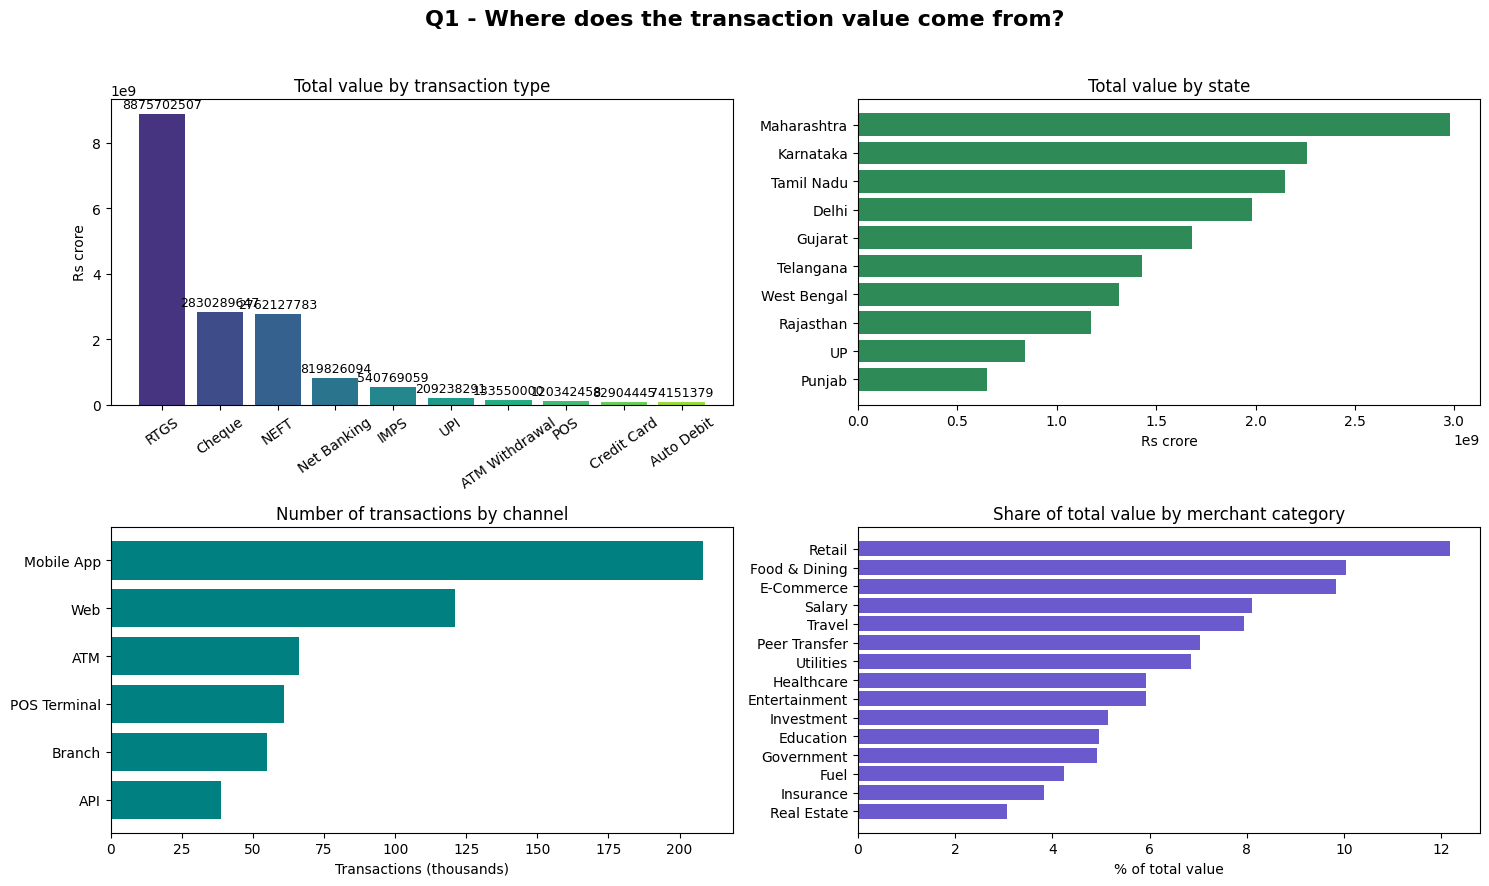

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle('Q1 - Where does the transaction value come from?', fontsize=16, fontweight='bold')

# (a) value by transaction type
t = type_summary['total_amount']
bars = axes[0, 0].bar(t.index.astype(str), t.values, color=plt.cm.viridis(np.linspace(0.15, 0.85, len(t))))
axes[0, 0].bar_label(bars, fmt='%.0f', padding=2, fontsize=9)
axes[0, 0].set_title('Total value by transaction type')
axes[0, 0].set_ylabel('Rs crore')
axes[0, 0].tick_params(axis='x', rotation=35)

# (b) value by state
s = (state_summary['total_amount']).sort_values()
axes[0, 1].barh(s.index.astype(str), s.values, color='seagreen')
axes[0, 1].set_title('Total value by state')
axes[0, 1].set_xlabel('Rs crore')

# (c) channel: transactions vs. value share
c = channel_summary.sort_values('transactions')
axes[1, 0].barh(c.index.astype(str), c['transactions'] / 1000, color='teal')
axes[1, 0].set_title('Number of transactions by channel')
axes[1, 0].set_xlabel('Transactions (thousands)')

# (d) merchant category
m = (merchant_summary['share_of_value_%']).sort_values()
axes[1, 1].barh(m.index.astype(str), m.values, color='slateblue')
axes[1, 1].set_title('Share of total value by merchant category')
axes[1, 1].set_xlabel('% of total value')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

What drives transaction value?

> Total value is about **₹1,645 crore**, but it is very unevenly spread.
>
> - **Transaction type — ticket size drives value, not frequency.** **RTGS** carries **54 %** of all value from only 6 % of transactions (average ₹2.7 lakh). **Cheque (17 %) and NEFT (17 %)**. **UPI** is the most *frequently* used type (154k transactions, 28 %) but moves just **1.3 %** of the value (average ≈ ₹1,360).
> - **Channel — volume, not size.** **Mobile App** leads (≈ 38 % of value and of transactions), followed by **Web** (22 %). Average ticket size is almost identical across channels (₹29k–30k), so the ranking simply mirrors how many transactions each channel handles.
> - **State.** **Maharashtra (18 %)**, **Karnataka (14 %)**, **Tamil Nadu (13 %)** and **Delhi (12 %)** together produce ≈ **57 %** of value; **Punjab (4 %)** and **UP (5 %)** are the smallest. Average ticket size is similar everywhere (≈ ₹29k–31k), so differences come from transaction counts.
> - **Merchant category.** Value is spread fairly evenly: **Retail (12 %)**, **Food & Dining (10 %)** and **E-Commerce (10 %)** lead, and **Real Estate (3 %)** is lowest. No single category dominates.
> - **Concentration.** Only **10 % of transactions (those above ₹50,000)** carry **≈ 85 % of the value**. Transactions of ₹5 lakh and above are just 1.1 % of the count yet carry **≈ 36 %** of the value.
> - **Debit vs Credit.** Two-thirds of transactions are debits, but credits are larger on average (≈ ₹42.6k vs ₹23.7k), so value is close to balanced (53 % debit / 47 % credit).

# **Q2 — How do transactions trend over time?**

# Time-series index and date-based selection

In [43]:
ts = df.set_index('transaction_datetime').sort_index()

print(type(ts.index).__name__, '|', ts.index.min(), '->', ts.index.max())
print('\nAll of 2021                       :', len(ts.loc['2021']))
print('March - June 2022                 :', len(ts.loc['2022-03':'2022-06']))
print('Single day (2020-12-25)           :', len(ts.loc['2020-12-25']))
print('Night transactions (22:00-05:00)  :', len(ts.between_time('22:00', '05:00')))

DatetimeIndex | 2019-01-01 00:01:00 -> 2024-01-01 23:58:00

All of 2021                       : 110024
March - June 2022                 : 36792
Single day (2020-12-25)           : 285
Night transactions (22:00-05:00)  : 161187


# Monthly, quarterly and yearly trends (`resample`)

`MS` = month start, `QS` = quarter start, `YS` = year start.

In [44]:
monthly = ts.resample('MS').agg(
    transactions=('transaction_id', 'count'),
    total_amount=('transaction_amount', 'sum'),
    avg_amount=('transaction_amount', 'mean'),
    fraud_cases=('is_fraud', 'sum'),
)
monthly['fraud_rate'] = monthly['fraud_cases'] / monthly['transactions'] * 100

# Jan 2024 contains a single day, so it is an incomplete month: drop it from trend analysis
monthly = monthly[monthly.index < '2024-01-01']
print(f'Monthly series: {monthly.index.min().date()} -> {monthly.index.max().date()} ({len(monthly)} months)')

quarterly = ts['transaction_amount'].resample('QS').sum().loc[:'2023-12-31']
yearly = ts['transaction_amount'].resample('YS').agg(['count', 'sum', 'mean'])
yearly.index = yearly.index.year
yearly = yearly.loc[:2023]                      # 2024 holds only 1 January

print('\nYearly summary:')
display(yearly)
print('Quarterly value (Rs crore), first 4 quarters:')
print((quarterly.head(4)).round(1))
# Frequency conversion: weekly totals -> daily frequency (forward-filled)
weekly = ts['transaction_amount'].resample('W').sum()
print('\nWeekly points:', len(weekly), '-> after asfreq("D", method="ffill"):', len(weekly.asfreq('D', method='ffill')))

Monthly series: 2019-01-01 -> 2023-12-01 (60 months)

Yearly summary:


,count,sum,mean
transaction_datetime,,,
2019,110083,"3,258,465,232.49","29,600.08"
2020,109767,"3,315,647,465.35","30,206.23"
2021,110024,"3,253,234,935.54","29,568.41"
2022,110247,"3,344,988,460.30","30,340.86"
2023,109584,"3,265,949,139.69","29,803.16"


Quarterly value (Rs crore), first 4 quarters:
transaction_datetime
2019-01-01   753,338,127.80
2019-04-01   813,993,379.90
2019-07-01   874,196,377.20
2019-10-01   816,937,347.70
Freq: QS-JAN, Name: transaction_amount, dtype: float64

Weekly points: 262 -> after asfreq("D", method="ffill"): 1828


# Seasonality, hour of day and weekday

In [46]:
# Average number of transactions per calendar month
seasonal = monthly.groupby(monthly.index.month)['transactions'].mean().round(0)
seasonal.index.name = 'month'
print('Average transactions per calendar month:')
display(seasonal.to_frame().T)

# Hour of day, time-of-day bucket, weekday
hourly = df.groupby('hour').agg(transactions=('transaction_id', 'count'),
                                avg_amount=('transaction_amount', 'mean'))
by_tod = df.groupby('time_of_day', observed=True)['transaction_id'].count().rename('transactions')
print('\nBy time of day:');  print(by_tod.to_frame())
print('By weekday:');
print(f"Busiest hour: {hourly['transactions'].idxmax()}:00 ({hourly['transactions'].max():,}) | "
      f"quietest hour: {hourly['transactions'].idxmin()}:00 ({hourly['transactions'].min():,})")

Average transactions per calendar month:


month,1,2,3,4,5,6,7,8,9,10,11,12
transactions,"9,374.00","8,408.00","9,266.00","8,966.00","9,344.00","9,083.00","9,384.00","9,401.00","9,011.00","9,365.00","9,051.00","9,287.00"



By time of day:
                   transactions
time_of_day                    
Night (0-5)              137167
Morning (6-11)           137987
Afternoon (12-17)        137394
Evening (18-23)          137452
By weekday:
Busiest hour: 8:00 (23,242) | quietest hour: 5:00 (22,514)


# Charts

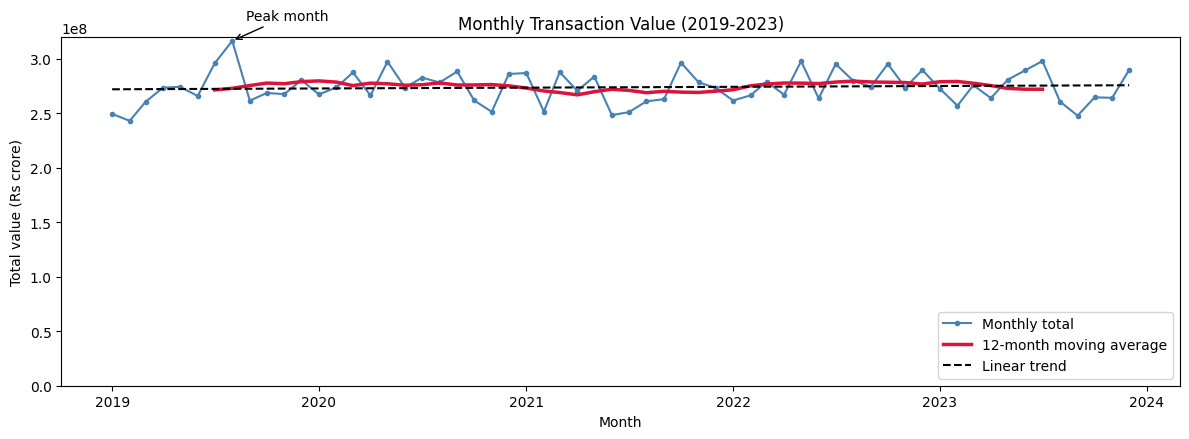

In [48]:
#Monthly value with a 12-month moving average and a fitted linear trend
value = monthly['total_amount']
x = np.arange(len(value))
slope, intercept = np.polyfit(x, value.values, 1)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(value.index, value.values, color='steelblue', linewidth=1.5, marker='o', markersize=3, label='Monthly total')
ax.plot(value.index, value.rolling(12, center=True).mean(), color='crimson', linewidth=2.5, label='12-month moving average')
ax.plot(value.index, slope * x + intercept, color='black', linestyle='--', label='Linear trend')
peak = value.idxmax()
ax.annotate('Peak month', xy=(peak, value.max()), xytext=(10, 15),
            textcoords='offset points', arrowprops=dict(arrowstyle='->'))
ax.set_ylim(0)
ax.set_title('Monthly Transaction Value (2019-2023)')
ax.set_xlabel('Month'); ax.set_ylabel('Total value (Rs crore)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

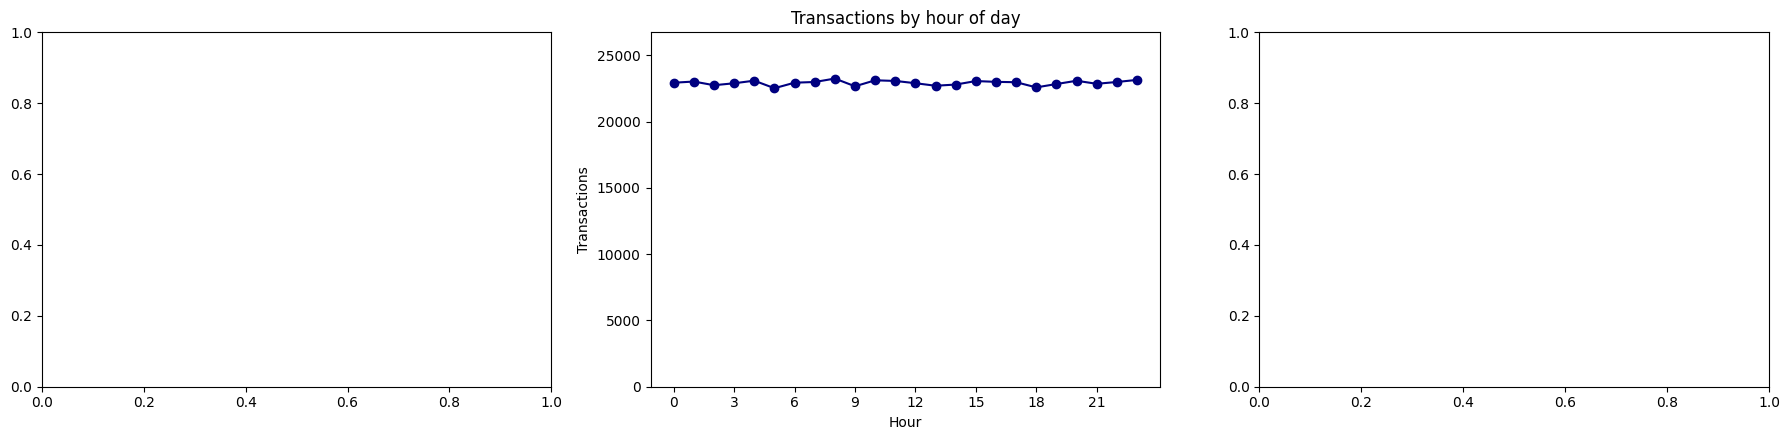

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
#Transactions by hour (y-axis from zero so tiny differences are not exaggerated)
axes[1].plot(hourly.index, hourly['transactions'], marker='o', color='navy')
axes[1].set_ylim(0, hourly['transactions'].max() * 1.15)
axes[1].set_xticks(range(0, 24, 3))
axes[1].set_title('Transactions by hour of day')
axes[1].set_xlabel('Hour'); axes[1].set_ylabel('Transactions')

plt.tight_layout(); plt.show()

How do transactions trend over time?

> **Activity is remarkably stable. There is no growth trend, no strong seasonality and no rush hour.**
>
> - **Yearly:** every year from 2019 to 2023 has ≈ **110,000 transactions** and **₹325–335 crore** of value (highest: 2022). There is no year-on-year growth.
> - **Trend test:** the fitted trend line adds only **≈ 1.4 % over five years** (p = 0.59 for value, p = 0.81 for transaction count), so it is **not statistically different from zero**. The 12-month moving average stays level.
> - **Monthly / quarterly:** monthly value moves in a narrow band (about **₹24–32 crore**, ±6 % around the mean) and monthly volume stays around **9,000–9,400 transactions**. **February is the only dip** (≈ 8,400 transactions), simply because it has fewer days.
> - **Hour of day:** all four time-of-day blocks hold ≈ 137,000–138,000 transactions each. Hour 8 is the busiest and hour 5 the quietest, but the gap is tiny (≈ 23,200 vs 22,500), so there is no real peak hour. Night-time (22:00–05:00) activity is as common as daytime.
> - **Weekday:** each weekday has ≈ 78,300–78,800 transactions (Friday busiest by a hair); weekends are as active as weekdays.




# Q3 — Is fraud linked to channel, hour, KYC status, credit score or transaction type?

In [51]:
fraud_total = df['is_fraud'].sum()
fraud_rate = df['is_fraud'].mean() * 100
fraud_value = df.loc[df['is_fraud'] == 1, 'transaction_amount'].sum()

print(f'Overall fraud rate : {fraud_rate:.3f}%  ({fraud_total:,} of {len(df):,} transactions)')
print(f'Money in fraud     : Rs {fraud_value:,.2f} crore = {fraud_value / total_value * 100:.2f}% of total value')
print(f"Customers affected : {df.loc[df['is_fraud'] == 1, 'customer_id'].nunique():,}")

Overall fraud rate : 0.886%  (4,873 of 550,000 transactions)
Money in fraud     : Rs 582,061,390.09 crore = 3.54% of total value
Customers affected : 4,722


In [53]:
def fraud_table(col):
    t = df.groupby(col, observed=True)['is_fraud'].agg(fraud_cases='sum', transactions='count')
    t['fraud_rate_%'] = t['fraud_cases'] / t['transactions'] * 100
    return t.sort_values('fraud_rate_%', ascending=False)

for col in ['transaction_type', 'channel', 'kyc_status', 'credit_rating', 'time_of_day', 'account_type']:
    print(f'--- Fraud by {col} ---')
    print(fraud_table(col).round(3))

--- Fraud by transaction_type ---
                  fraud_cases  transactions  fraud_rate_%
transaction_type                                         
RTGS                      611         32964          1.85
Cheque                    256         21711          1.18
NEFT                      581         66615          0.87
Credit Card               140         16426          0.85
Net Banking               326         38458          0.85
ATM Withdrawal            456         55106          0.83
IMPS                      624         77038          0.81
POS                       481         60278          0.80
UPI                      1211        153986          0.79
Auto Debit                187         27418          0.68
--- Fraud by channel ---
              fraud_cases  transactions  fraud_rate_%
channel                                              
Branch                520         54957          0.95
POS Terminal          557         60853          0.92
API                   346    

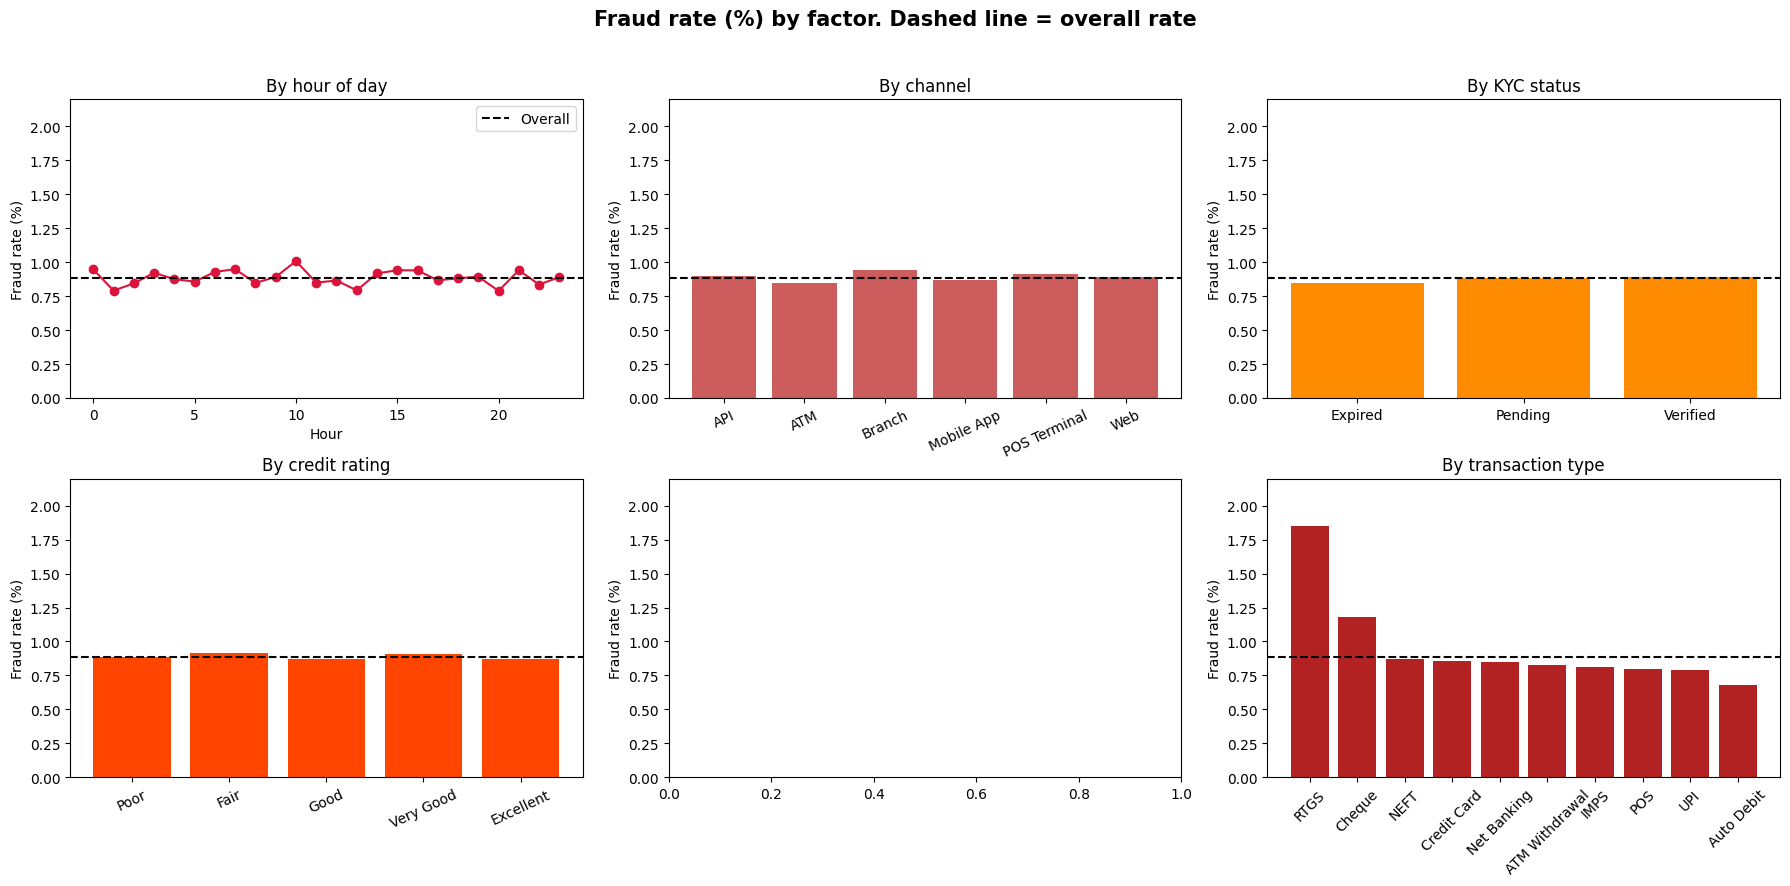

In [56]:
fraud_by_hour   = df.groupby('hour')['is_fraud'].mean() * 100
fraud_by_rating = df.groupby('credit_rating', observed=True)['is_fraud'].mean() * 100
fraud_by_kyc    = df.groupby('kyc_status', observed=True)['is_fraud'].mean() * 100
fraud_by_type   = (df.groupby('transaction_type', observed=True)['is_fraud'].mean() * 100).sort_values(ascending=False)
fraud_by_chan   = df.groupby('channel', observed=True)['is_fraud'].mean() * 100

YMAX = 2.2     # one common y-axis for every panel, so noise is not blown up and panels are comparable
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

axes[0, 0].plot(fraud_by_hour.index, fraud_by_hour.values, marker='o', color='crimson')
axes[0, 0].axhline(fraud_rate, color='black', linestyle='--', label='Overall'); axes[0, 0].legend()
axes[0, 0].set_title('By hour of day'); axes[0, 0].set_xlabel('Hour')

axes[0, 1].bar(fraud_by_chan.index.astype(str), fraud_by_chan.values, color='indianred')
axes[0, 1].axhline(fraud_rate, color='black', linestyle='--')
axes[0, 1].set_title('By channel'); axes[0, 1].tick_params(axis='x', rotation=25)

axes[0, 2].bar(fraud_by_kyc.index.astype(str), fraud_by_kyc.values, color='darkorange')
axes[0, 2].axhline(fraud_rate, color='black', linestyle='--')
axes[0, 2].set_title('By KYC status')

axes[1, 0].bar(fraud_by_rating.index.astype(str), fraud_by_rating.values, color='orangered')
axes[1, 0].axhline(fraud_rate, color='black', linestyle='--')
axes[1, 0].set_title('By credit rating'); axes[1, 0].tick_params(axis='x', rotation=25)

axes[1, 2].bar(fraud_by_type.index.astype(str), fraud_by_type.values, color='firebrick')
axes[1, 2].axhline(fraud_rate, color='black', linestyle='--')
axes[1, 2].set_title('By transaction type'); axes[1, 2].tick_params(axis='x', rotation=45)

for ax in axes.flat:
    ax.set_ylim(0, YMAX); ax.set_ylabel('Fraud rate (%)')
fig.suptitle('Fraud rate (%) by factor. Dashed line = overall rate', fontsize=15, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

           transactions  fraud_cases  fraud_rate_pct
fine_band                                           
up to 1L         513921         4117            0.80
1L - 2.5L         20583          165            0.80
2.5L - 5L          9471           96            1.01
5L - 10L           4279          351            8.20
10L - 25L          1527          126            8.25
above 25L           219           18            8.22


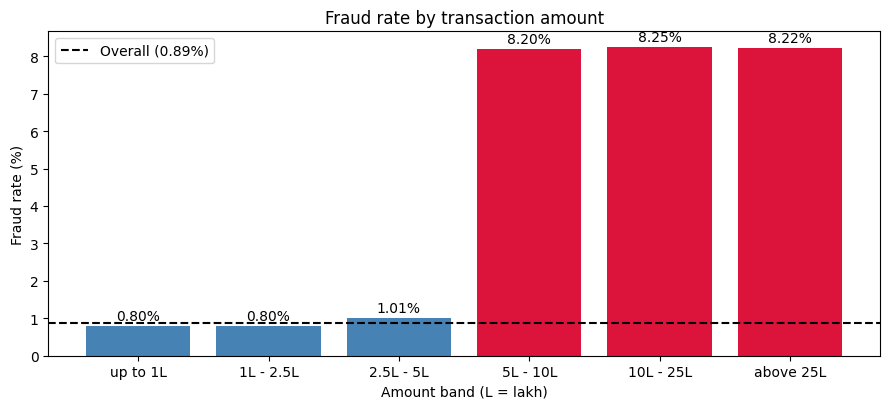

In [57]:
fine_bins = [0, 1e5, 2.5e5, 5e5, 1e6, 2.5e6, np.inf]
fine_labels = ['up to 1L', '1L - 2.5L', '2.5L - 5L', '5L - 10L', '10L - 25L', 'above 25L']
df['fine_band'] = pd.cut(df['transaction_amount'], bins=fine_bins, labels=fine_labels)

fine = df.groupby('fine_band', observed=True).agg(
    transactions=('transaction_id', 'count'),
    fraud_cases=('is_fraud', 'sum'),
    fraud_rate_pct=('is_fraud', lambda x: x.mean() * 100),
)
print(fine)

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(fine.index.astype(str), fine['fraud_rate_pct'],
              color=['steelblue'] * 3 + ['crimson'] * 3)
ax.bar_label(bars, fmt='%.2f%%', padding=2)
ax.axhline(fraud_rate, color='black', linestyle='--', label=f'Overall ({fraud_rate:.2f}%)')
ax.set_title('Fraud rate by transaction amount'); ax.set_xlabel('Amount band (L = lakh)'); ax.set_ylabel('Fraud rate (%)')
ax.legend()
plt.tight_layout(); plt.show()

In [58]:
THRESHOLD = 5e5          # Rs 5 lakh: where the fraud rate jumps
df['high_value'] = df['transaction_amount'] >= THRESHOLD
hv, fraud_mask = df['high_value'], df['is_fraud'] == 1

print(f"Transactions >= Rs 5 lakh : {hv.sum():,} ({hv.mean() * 100:.2f}% of all)  | fraud rate {df.loc[hv, 'is_fraud'].mean() * 100:.2f}%")
print(f"Transactions <  Rs 5 lakh : {(~hv).sum():,}  | fraud rate {df.loc[~hv, 'is_fraud'].mean() * 100:.2f}%")
print(f"\nShare of all fraud CASES that are >= Rs 5 lakh : {(hv & fraud_mask).sum() / fraud_mask.sum() * 100:.1f}%")
print(f"Share of fraud MONEY that is >= Rs 5 lakh      : {df.loc[hv & fraud_mask, 'transaction_amount'].sum() / df.loc[fraud_mask, 'transaction_amount'].sum() * 100:.1f}%")

# Same question, per transaction type
type_size = df.pivot_table(index='transaction_type', columns='high_value', values='is_fraud',
                           aggfunc='mean', observed=True) * 100
type_size.columns = ['Below Rs 5 lakh', 'Rs 5 lakh and above']
type_size['txns >= 5 lakh'] = df[hv].groupby('transaction_type', observed=True).size()
type_size['% of type >= 5 lakh'] = type_size['txns >= 5 lakh'] / df['transaction_type'].value_counts() * 100
print('\nFraud rate (%) by transaction type and size:')
type_size.fillna(0).round(2)

Transactions >= Rs 5 lakh : 6,025 (1.10% of all)  | fraud rate 8.22%
Transactions <  Rs 5 lakh : 543,975  | fraud rate 0.80%

Share of all fraud CASES that are >= Rs 5 lakh : 10.2%
Share of fraud MONEY that is >= Rs 5 lakh      : 84.2%

Fraud rate (%) by transaction type and size:


,Below Rs 5 lakh,Rs 5 lakh and above,txns >= 5 lakh,% of type >= 5 lakh
transaction_type,,,,
ATM Withdrawal,0.83,0.00,0.00,0.00
Auto Debit,0.68,0.00,0.00,0.00
Cheque,0.86,6.91,"1,129.00",5.20
Credit Card,0.85,0.00,0.00,0.00
IMPS,0.81,33.33,3.00,0.00
NEFT,0.80,9.52,546.00,0.82
Net Banking,0.84,7.94,63.00,0.16
POS,0.80,0.00,0.00,0.00
RTGS,0.88,8.38,"4,284.00",13.00


In [59]:
df['size_class'] = np.where(df['transaction_amount'] > 100000, 'Above Rs 1 lakh', 'Up to Rs 1 lakh')

type_size = df.pivot_table(index='transaction_type', columns='size_class',
                           values='is_fraud', aggfunc='mean', observed=True) * 100
type_size['txns above 1 lakh'] = df[df['size_class'] == 'Above Rs 1 lakh'].groupby('transaction_type', observed=True).size()
print('Fraud rate (%) by transaction type and size:')
display(type_size.fillna(0).round(2))

by_size = df.groupby('size_class')['is_fraud'].mean() * 100
print(f"Overall: up to Rs 1 lakh = {by_size['Up to Rs 1 lakh']:.2f}%  |  above Rs 1 lakh = {by_size['Above Rs 1 lakh']:.2f}%")

hv = df['transaction_amount'] > 50000
print(f"\nFraud rate, transactions above Rs 50,000: {df.loc[hv, 'is_fraud'].mean() * 100:.3f}%  vs  "
      f"{df.loc[~hv, 'is_fraud'].mean() * 100:.3f}% for the rest")

Fraud rate (%) by transaction type and size:


size_class,Above Rs 1 lakh,Up to Rs 1 lakh,txns above 1 lakh
transaction_type,,,
ATM Withdrawal,0.00,0.83,0.00
Auto Debit,0.00,0.68,0.00
Cheque,1.88,0.93,"5,755.00"
Credit Card,0.00,0.85,17.00
IMPS,1.52,0.81,263.00
NEFT,1.54,0.81,"6,032.00"
Net Banking,1.70,0.82,"1,415.00"
POS,0.00,0.80,2.00
RTGS,2.33,0.81,"22,594.00"


Overall: up to Rs 1 lakh = 0.80%  |  above Rs 1 lakh = 2.10%

Fraud rate, transactions above Rs 50,000: 1.635%  vs  0.801% for the rest


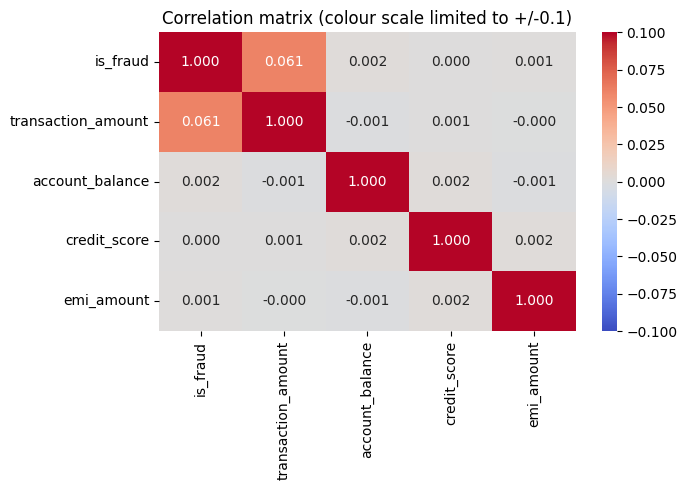

Credit score vs amount, correlation inside each transaction type:
transaction_type
ATM Withdrawal    0.01
Auto Debit        0.00
Cheque            0.01
Credit Card      -0.01
IMPS              0.00
NEFT              0.00
Net Banking       0.00
POS               0.00
RTGS             -0.01
UPI               0.00


In [60]:
corr_cols = ['is_fraud', 'transaction_amount', 'account_balance', 'credit_score', 'emi_amount']
corr = df[corr_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0, vmin=-0.1, vmax=0.1)
plt.title('Correlation matrix (colour scale limited to +/-0.1)')
plt.tight_layout(); plt.show()

print('Credit score vs amount, correlation inside each transaction type:')
print(df.groupby('transaction_type', observed=True)
        .apply(lambda g: g['credit_score'].corr(g['transaction_amount']), include_groups=False).round(3).to_string())

###Is fraud linked to channel, hour, KYC, credit score or transaction type?

> The overall fraud rate is **0.89 %** (4,873 of 550,000 transactions), but fraud involves **₹58 crore, i.e. 3.5 % of all value**: fraud is about **four times more concentrated in money terms than in transaction counts**, which means the fraud that does the damage is large.
>
> | Factor | Fraud-rate range | Linked to fraud? |
> |---|---|---|
> | **Channel** | 0.85 % – 0.95 % |❌ No |
> | **Hour of day** | ≈ 0.8 % – 1.0 %, no pattern |❌ No: night is not riskier than day |
> | **KYC status** | Verified 0.89 %, Pending 0.89 %, Expired 0.84 % |❌ No: incomplete KYC is *not* riskier |
> | **Credit score / rating** | 0.87 % – 0.91 %; correlation ≈ 0 |❌ No |
> | **State, account type, merchant category, weekday, year** | all ≈ 0.7 % – 0.95 % |❌ No |
> | **Transaction type** | **RTGS 1.85 %**, **Cheque 1.18 %**, others 0.68 % – 0.87 % |✅ Yes, but it is a proxy for amount |
> | **Transaction amount** | **≈ 0.8 % up to ₹2.5 lakh → ≈ 8 % above ₹5 lakh** |✅ **Yes: the real driver** |
>
> **The amount effect is a threshold, not a slope.** The fraud rate is flat at ≈ 0.80 % for everything up to ₹2.5 lakh, about 1.0 % between ₹2.5 and 5 lakh, and then **jumps roughly 10-fold to ≈ 8.2 %** for transactions of ₹5 lakh and above. Those 6,025 transactions are only **1.1 % of the total**, but they contain **10 % of all fraud cases and 84 % of all fraud money**.
>
> **Why the type effect is really an amount effect:** only RTGS, Cheque, NEFT, Net Banking and IMPS ever reach ₹5 lakh (13 % of RTGS and 5 % of Cheque transactions do; UPI, POS, ATM, Credit Card and Auto Debit never do). RTGS and Cheque look riskier simply because more of their transactions are large.
>
> **A typical fraud is not large.** The median fraudulent transaction (≈ ₹2,700) is similar to the median normal one (≈ ₹2,000); about **90 % of fraud cases are below ₹5 lakh** and look just like normal traffic. The *average* fraud is four times larger (≈ ₹1.2 lakh vs ≈ ₹29k) only because a minority of very large cases pull it up.


# **Q4 — How often do transactions fail, and where?**

In [61]:
status_summary = pd.DataFrame({
    'transactions': df['transaction_status'].value_counts(),
    'percentage': df['transaction_status'].value_counts(normalize=True) * 100,
})
display(status_summary)

df['failed'] = (df['transaction_status'] == 'Failed').astype('int8')
fail_channel = df.groupby('channel', observed=True)['failed'].mean() * 100
fail_hour = df.groupby('hour')['failed'].mean() * 100
fail_type = (df.groupby('transaction_type', observed=True)['failed'].mean() * 100).sort_values(ascending=False)

print(f"\nValue of failed transactions: Rs {df.loc[df['failed'] == 1, 'transaction_amount'].sum():,.0f} crore")
print(f'Failure rate by channel : {fail_channel.min():.2f}% - {fail_channel.max():.2f}%')
print(f'Failure rate by hour    : {fail_hour.min():.2f}% - {fail_hour.max():.2f}%')
print(f'Failure rate by type    : {fail_type.min():.2f}% - {fail_type.max():.2f}%')

,transactions,percentage
transaction_status,,
Success,506247,92.04
Failed,21905,3.98
Reversed,11019,2.00
Pending,10829,1.97



Value of failed transactions: Rs 696,850,444 crore
Failure rate by channel : 3.93% - 4.12%
Failure rate by hour    : 3.67% - 4.28%
Failure rate by type    : 3.87% - 4.21%


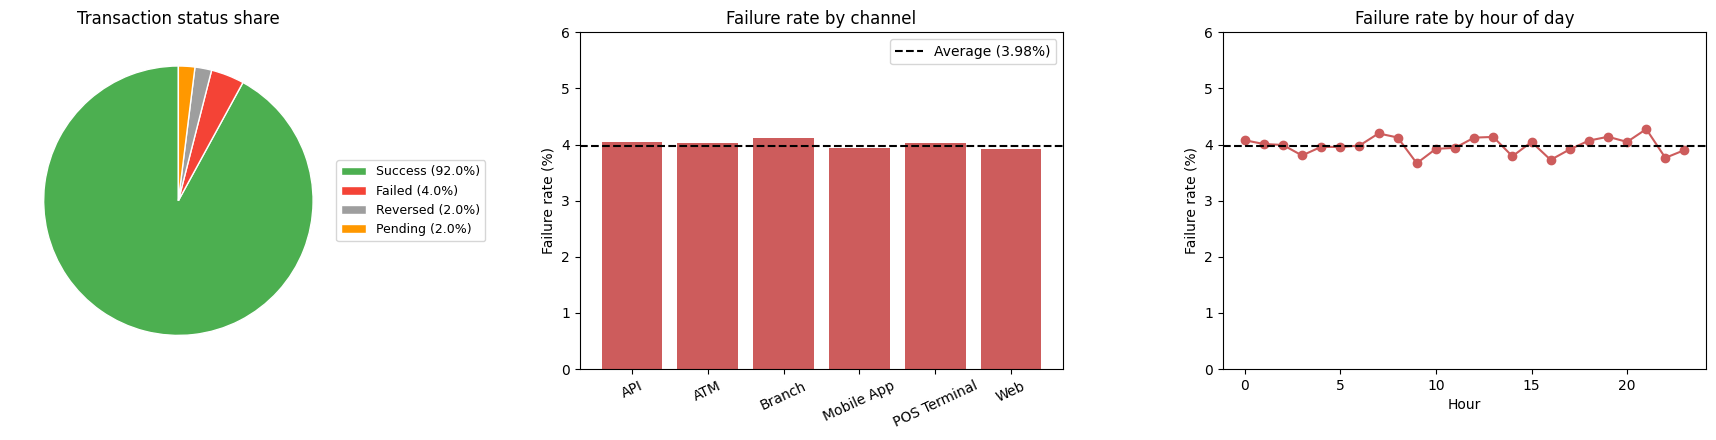

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
avg_fail = df['failed'].mean() * 100

# (a) status share
colors = {'Success': '#4caf50', 'Failed': '#f44336', 'Pending': '#ff9800', 'Reversed': '#9e9e9e'}
sc = df['transaction_status'].value_counts()
axes[0].pie(sc, startangle=90, colors=[colors[k] for k in sc.index], wedgeprops={'edgecolor': 'white'})
axes[0].legend([f'{k} ({v / sc.sum() * 100:.1f}%)' for k, v in sc.items()],
               loc='center left', bbox_to_anchor=(0.95, 0.5), fontsize=9)
axes[0].set_title('Transaction status share')

# (b) failure rate by channel
axes[1].bar(fail_channel.index.astype(str), fail_channel.values, color='indianred')
axes[1].axhline(avg_fail, color='black', linestyle='--', label=f'Average ({avg_fail:.2f}%)')
axes[1].set_ylim(0, 6); axes[1].set_ylabel('Failure rate (%)'); axes[1].legend(loc='upper right')
axes[1].set_title('Failure rate by channel'); axes[1].tick_params(axis='x', rotation=25)

# (c) failure rate by hour
axes[2].plot(fail_hour.index, fail_hour.values, marker='o', color='indianred')
axes[2].axhline(avg_fail, color='black', linestyle='--')
axes[2].set_ylim(0, 6); axes[2].set_xlabel('Hour'); axes[2].set_ylabel('Failure rate (%)')
axes[2].set_title('Failure rate by hour of day')

plt.tight_layout(); plt.show()

How often do transactions fail, and where?

> - **92.0 %** of transactions succeed. **4.0 %** fail (≈ 21,900), **2.0 %** are reversed and **2.0 %** are still pending, so about **1 in 12 transactions does not complete cleanly**.
> - **Failures are not concentrated anywhere.** The failure rate is ≈ **4 % for every channel** (3.9 % – 4.1 %), every transaction type (3.9 % – 4.2 %) and stays within roughly **3.7 % – 4.3 % at every hour** of the day.
> - **None of the differences is statistically significant** (chi-square p = 0.32 for channel, 0.09 for hour, 0.51 for type, 0.27 for state, 0.54 for KYC status). The fluctuations are random noise, not a night-time or channel-specific problem.
> - **Money impact:** failed transactions hold **≈ ₹70 crore, i.e. 4.2 % of all value**. This is close to the 4.0 % share by count, so large payments are not much more likely to fail. The failure rate edges up from 3.9 % (micro) to 4.2 % (above ₹1 lakh), but this is only borderline significant (p = 0.06).
>


# **Q5 — What does the typical customer look like?**

# Credit score and rating

In [63]:
print(df['credit_score'].describe().round(1))

credit_summary = df.groupby('credit_rating', observed=True).agg(
    transactions=('transaction_id', 'count'),
    customers=('customer_id', 'nunique'),
    average_transaction=('transaction_amount', 'mean'),
    fraud_rate_pct=('is_fraud', lambda x: x.mean() * 100),
)
credit_summary['share_of_transactions_%'] = credit_summary['transactions'] / credit_summary['transactions'].sum() * 100
credit_summary

count   550,000.00
mean        599.80
std         173.10
min         300.00
25%         450.00
50%         600.00
75%         750.00
max         899.00
Name: credit_score, dtype: float64


,transactions,customers,average_transaction,fraud_rate_pct,share_of_transactions_%
credit_rating,,,,,
Poor,257168,76827,"29,751.14",0.88,46.76
Fair,83064,51558,"29,949.85",0.91,15.10
Good,64016,44007,"29,217.01",0.87,11.64
Very Good,54793,39827,"29,869.82",0.91,9.96
Excellent,90959,54224,"30,817.10",0.87,16.54


# Loans

In [64]:
print(f"Share of transactions made by customers with a loan: {df['has_loan'].mean() * 100:.1f}%")

loan_summary = df.groupby('loan_type', observed=True).agg(
    transactions=('transaction_id', 'count'),
    average_emi=('emi_amount', 'mean'),
    average_transaction=('transaction_amount', 'mean'),
    avg_credit_score=('credit_score', 'mean'),
).sort_values('transactions', ascending=False)
loan_summary

Share of transactions made by customers with a loan: 35.0%


,transactions,average_emi,average_transaction,avg_credit_score
loan_type,,,,
No Loan,357712,0.00,"29,879.94",599.67
Personal,47810,"6,789.41","29,476.53",599.56
Home,38252,"6,756.46","29,289.61",600.13
Auto,29219,"6,780.03","30,004.09",599.68
Business,28863,"6,764.13","30,909.88",600.82
Unknown,19422,"6,697.62","29,247.92",602.75
Education,19074,"6,765.95","31,695.39",597.73
Gold,9648,"6,809.63","29,993.34",600.20


In [65]:
df['account_balance'].describe(percentiles=[.25, .5, .75, .9, .99]).round(0)

,account_balance
count,"550,000.00"
mean,"84,550.00"
std,"170,915.00"
min,500.00
25%,"15,158.00"
50%,"36,423.00"
75%,"87,607.00"
90%,"192,536.00"
99%,"746,757.00"
max,"5,000,000.00"


In [66]:
customer_summary = df.groupby('customer_id').agg(
    transactions=('transaction_id', 'count'),
    total_amount=('transaction_amount', 'sum'),
    average_balance=('account_balance', 'mean'),
    fraud_transactions=('is_fraud', 'sum'),
)

print('Unique customers                        :', f'{len(customer_summary):,}')
print('Average transactions per customer       :', round(customer_summary['transactions'].mean(), 2))
print('Customers with at least one fraud case  :', f"{(customer_summary['fraud_transactions'] > 0).sum():,} "
      f"({(customer_summary['fraud_transactions'] > 0).mean() * 100:.1f}%)")

# Data-quality check: do customer attributes stay the same across their transactions?
print('\nAverage number of DIFFERENT credit scores per customer:',
      round(df.groupby('customer_id')['credit_score'].nunique().mean(), 2))

print('\nTop 5 customers by total value:')
customer_summary.sort_values('total_amount', ascending=False).head(5)

Unique customers                        : 79,916
Average transactions per customer       : 6.88
Customers with at least one fraud case  : 4,722 (5.9%)

Average number of DIFFERENT credit scores per customer: 6.84

Top 5 customers by total value:


,transactions,total_amount,average_balance,fraud_transactions
customer_id,,,,
CUST038846,12,"10,169,933.88","76,797.49",0
CUST003107,7,"10,022,645.83","39,234.83",0
CUST053927,6,"10,010,139.02","117,305.08",0
CUST061467,5,"10,002,756.74","74,888.50",0
CUST075635,6,"9,430,525.65","65,490.39",0


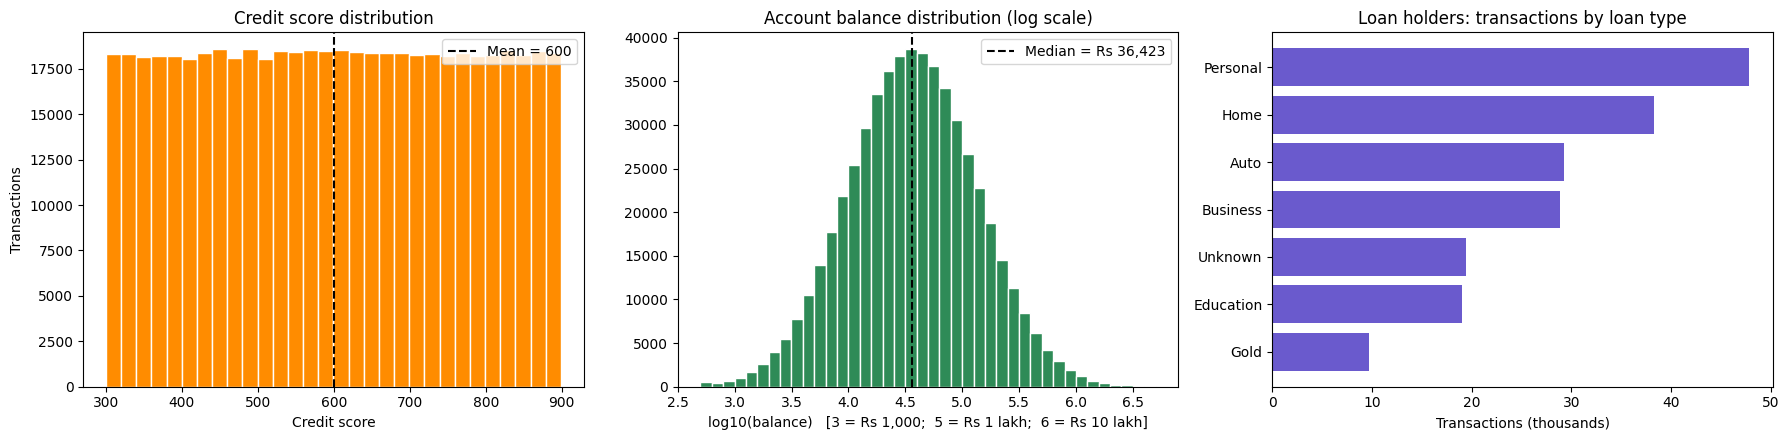

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(df['credit_score'], bins=30, color='darkorange', edgecolor='white')
axes[0].axvline(df['credit_score'].mean(), color='black', linestyle='--', label=f"Mean = {df['credit_score'].mean():.0f}")
axes[0].set_title('Credit score distribution')
axes[0].set_xlabel('Credit score'); axes[0].set_ylabel('Transactions'); axes[0].legend()

axes[1].hist(np.log10(df['account_balance']), bins=40, color='seagreen', edgecolor='white')
axes[1].axvline(np.log10(df['account_balance'].median()), color='black', linestyle='--',
                label=f"Median = Rs {df['account_balance'].median():,.0f}")
axes[1].set_title('Account balance distribution (log scale)')
axes[1].set_xlabel('log10(balance)   [3 = Rs 1,000;  5 = Rs 1 lakh;  6 = Rs 10 lakh]'); axes[1].legend()

lt = loan_summary.drop('No Loan')['transactions'].sort_values()
axes[2].barh(lt.index.astype(str), lt.values / 1000, color='slateblue')
axes[2].set_title('Loan holders: transactions by loan type')
axes[2].set_xlabel('Transactions (thousands)')

plt.tight_layout(); plt.show()

What does the typical customer look like?

> - **Customers:** 79,916 distinct customer IDs making **≈ 6.9 transactions each** (typically 5 to 9; the maximum is 20). About **6 % (4,722)** have been involved in at least one fraudulent transaction.
> - **Customer value is concentrated:** the **top 10 % of customers generate ≈ 50 % of the value** and the top 20 % generate ≈ 69 %, driven by those who make large RTGS, Cheque and NEFT payments.
> - **Credit score:** evenly spread from 300 to 899 (quartiles 450 / 600 / 750, mean ≈ 600), i.e. there is no "typical" score. **Poor is the largest rating (≈ 47 % of transactions)** only because the Poor band (300 – 579) is much wider than the other bands, not because the customer base is unusually weak. Credit rating has **no relationship** with transaction size or fraud.
> - **Loans:** about **35 % of transactions** come from customers who have a loan. **Personal** loans are the most common type, then **Home**, **Auto** and **Business**, with **Education** and **Gold** loans the smallest groups. The average EMI is nearly the same for every loan type (**≈ ₹6,700 – 6,800**), and average credit score (≈ 600) does not differ between loan types.
> - **Balances:** very skewed. The **median balance is ≈ ₹36,400** but the **mean is ≈ ₹84,600**, pulled up by a minority of accounts that hold up to ₹50 lakh (the top 1 % hold more than ≈ ₹7.5 lakh). A typical record is therefore a mid-range account (≈ ₹15,000 – ₹88,000 balance) making small everyday payments (median transaction ≈ ₹2,000).


In [68]:
print('KEY NUMBERS')
print('=' * 58)
print(f"Transactions analysed        : {len(df):,}")
print(f"Period                       : {df['transaction_date'].min().date()} to {df['transaction_date'].max().date()}")
print(f"Total value                  : Rs {total_value:,.0f} crore")
print(f"Success rate                 : {(df['transaction_status'] == 'Success').mean() * 100:.1f}%")
print(f"Failure rate                 : {df['failed'].mean() * 100:.2f}%")
print(f"Fraud rate                   : {fraud_rate:.3f}%  (Rs {fraud_value:,.0f} crore)")
print(f"Top state by value           : {state_summary['total_amount'].idxmax()}")
print(f"Top channel by value         : {channel_summary['total_amount'].idxmax()}")
print(f"Most frequent type           : {df['transaction_type'].value_counts().idxmax()}")
print(f"Top type by value            : {type_summary['total_amount'].idxmax()}")
print(f"Top merchant category        : {merchant_summary['total_amount'].idxmax()}")

KEY NUMBERS
Transactions analysed        : 550,000
Period                       : 2019-01-01 to 2024-01-01
Total value                  : Rs 16,448,901,664 crore
Success rate                 : 92.0%
Failure rate                 : 3.98%
Fraud rate                   : 0.886%  (Rs 582,061,390 crore)
Top state by value           : Maharashtra
Top channel by value         : Mobile App
Most frequent type           : UPI
Top type by value            : RTGS
Top merchant category        : Retail


## Summary of findings

| Question | Answer|
|---|---|
| **Q1 – Value drivers** | **Ticket size, not frequency.** RTGS, Cheque and NEFT carry ≈ 88 % of value; 10 % of transactions (> ₹50k) carry ≈ 85 %. Maharashtra, Karnataka, Tamil Nadu and Delhi make up ≈ 57 %. Mobile App is the top channel by volume. |
| **Q2 – Trends** | **Flat.** ≈ 110k transactions and ₹325–335 crore every year; the trend (+1.4 % over 5 years, p = 0.59) is not significant. No seasonality and no peak hour. |
| **Q3 – Fraud** | **Amount is the driver, as a threshold.** ≈ 0.8 % fraud up to ₹2.5 lakh, ≈ 8 % from ₹5 lakh up (84 % of fraud money). Channel, hour, KYC, credit score, state and account type show no significant link. |
| **Q4 – Failures** | **≈ 4 % fail, evenly everywhere** (no significant difference by channel, hour, type or state), pointing to a systemic cause. |
| **Q5 – Customers** | Evenly spread credit scores (mean ≈ 600), ≈ 35 % have a loan (Personal is most common), skewed balances (median ≈ ₹36k, mean ≈ ₹85k), top 10 % of customers ≈ 50 % of value. Customer IDs are not stable, so profiles are approximate. |

